# 05 · Query-based detector: RT-DETR

Covers the *Query-based* checkpoint.

**Same protocol and budget as YOLO (notebook 02, E1):** the identical exported training set, input 1280 px,
25 epochs, batch adjusted to memory, seed 42, COCO-pretrained weights, our evaluator on all 2 846 val frames.
Ultralytics' per-epoch val mAP (monitor subset, every 3rd val frame) is used **only** to compare training
dynamics with YOLO, because both report it the same way.

**Model:** RT-DETR-L (HGNetv2 backbone, hybrid encoder, 6-layer decoder), Ultralytics implementation.
Optimizer: AdamW, lr 1e-4, weight decay 1e-4, as in the RT-DETR paper. With `optimizer="auto"`
Ultralytics would pick SGD-type MuSGD with lr 0.01 for this many iterations, which DETR-style models do not train well with.

**Experiments**

| id | change | why |
|---|---|---|
| R0 | defaults: 300 queries, 100 denoising groups | baseline |
| R1 | 500 queries | dense frames (up to 180 objects, 01 §3.3) and the metric scores up to 500 detections; more queries = more candidates for small objects |
| R2 | R0 without denoising (`nd=0`) | the denoising loss stabilises bipartite matching early in training (DN-DETR); removing it shows its effect on convergence |

Not done: separate learning rates for backbone and transformer, which Ultralytics does not expose without a custom trainer.

**Runtime:** GPU. `SMOKE = True` first (~10 min), then `SMOKE = False`. Finished runs are skipped and an
interrupted one resumes, so after a disconnect just run everything again.

## 1. Setup

In [1]:
# --- Environment detection and paths (same as notebooks 01-03) -------------------------
import os, sys, glob, subprocess
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"   # Colab only: used to download the data

def find_repo():
    """Folder that contains the vdet/ package."""
    if IN_COLAB:  # anywhere on Google Drive (unzipping often adds an extra visdrone-det/ level)
        for depth in range(0, 4):
            hits = sorted(glob.glob("/content/drive/MyDrive/" + "*/" * depth + "vdet/__init__.py"))
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet/ not found on Google Drive: upload the visdrone-det folder to MyDrive")
    if IN_KAGGLE:
        for depth in range(1, 6):
            hits = glob.glob("/kaggle/input/" + "*/" * depth + "vdet/__init__.py")
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet not found: add the code dataset via '+ Add Input'")
    return os.path.abspath("..")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("VDET_WORK", "/content/drive/MyDrive/visdrone-work")  # results survive disconnects
    if not os.path.exists("/content/data/train"):
        # Kaggle API token, never written into the notebook (it goes to GitHub):
        # Colab sidebar -> key icon (Secrets) -> name KAGGLE_API_TOKEN, value KGAT_..., notebook access ON.
        # Fallback: a legacy kaggle.json in the MyDrive root.
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            !mkdir -p /root/.kaggle && cp /content/drive/MyDrive/kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json
        !pip -q install -U kaggle
        !kaggle competitions download -c {COMPETITION} -p /content -q
        !unzip -q -o /content/{COMPETITION}.zip -d /content/data && rm /content/{COMPETITION}.zip

# Ultralytics prints the model summary and a progress bar per epoch; keep the notebook output short.
# Per-epoch numbers are still saved to runs_yolo/<exp>/results.csv and plotted in section 4.
os.environ["YOLO_VERBOSE"] = "False"

for pkg, mod in [("pycocotools", "pycocotools"), ("ultralytics", "ultralytics")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

REPO_DIR = find_repo()
sys.path.insert(0, REPO_DIR)
print("repo:", REPO_DIR)

Mounted at /content/drive
repo: /content/drive/MyDrive/visdrone-det/visdrone-det


In [2]:
# --- Imports and configuration -------------------------------------------------------
import json, shutil, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import ultralytics
from ultralytics import RTDETR

from vdet import CLASSES
from vdet import data as D, evaluate as E, submission as S, viz as V, yolo_export as YX, ultra as U, analysis as AN
from vdet.paths import find_data_root, default_work_dir

SMOKE = False                 # True: tiny run to test the pipeline. False: the real experiments.
RUN = ["R0", "R1", "R2"]     # experiments for this session (finished ones are skipped)

SEED = 42
EPOCHS = 2 if SMOKE else 25  # same as YOLO
BATCH = 4                    # RT-DETR-L at 1280 px on a 16 GB T4; lower to 2 on out-of-memory
IMGSZ = 320 if SMOKE else 1280
TRAIN_STEP, VAL_MONITOR_STEP, EXPORT_SIDE = 5, 3, 1280   # identical to notebook 02
DEVICE = 0 if torch.cuda.is_available() else "cpu"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_ROOT = find_data_root()
WORK_DIR = default_work_dir()
TAG = "_smoke" if SMOKE else ""
RUNS_DIR = WORK_DIR / f"runs_rtdetr{TAG}"
YOLO_DS = (Path("/tmp") if IN_KAGGLE else Path("/content") if IN_COLAB else WORK_DIR) / f"yolo_ds{TAG}"   # shared with 02/03
FIG_DIR = WORK_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
log = U.ResultsLog(WORK_DIR / f"results_rtdetr{TAG}.json")

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device",
      torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

ultralytics 8.4.208 | torch 2.14.1+cu130 | device Tesla T4


## 2. Data: the same selection and export as notebooks 02 and 03

In [3]:
tv = D.load_train_val(DATA_ROOT)
im = tv.images
train_keys = D.subsample_frames(im[im.split == "train"], TRAIN_STEP).key
monitor_keys = D.subsample_frames(im[im.split == "val"], VAL_MONITOR_STEP).key
eval_keys = im[im.split == "val"].key
if SMOKE:
    train_keys = D.subsample_frames(im[im.split == "train"], 200).key
    monitor_keys = eval_keys = D.subsample_frames(im[im.split == "val"], 100).key
train, monitor, val = tv.subset(train_keys), tv.subset(monitor_keys), tv.subset(eval_keys)
if not (YOLO_DS / "data.yaml").exists():
    display(YX.export_yolo_dataset(train, monitor, YOLO_DS, mask_train=True, mask_val=False, max_side=EXPORT_SIDE))
print("train:", train, "\neval:", val)

export train:   0%|          | 0/4868 [00:00<?, ?it/s]

export val:   0%|          | 0/951 [00:00<?, ?it/s]

,images,masked_images,boxes,dropped_boxes
train,4868,3644,220357,2522
val,951,0,38206,0


train: SplitData(images=4868, boxes=222879, ignore=12898, clips=56) 
eval: SplitData(images=2846, boxes=114132, ignore=3995, clips=7)


## 3. Experiments
`decoder` settings are injected with `U.set_rtdetr_decoder` (the model yaml cannot pass them);
all other keys are Ultralytics training arguments.

In [4]:
COMMON = dict(epochs=EPOCHS, batch=BATCH, imgsz=IMGSZ, seed=SEED, deterministic=False, device=DEVICE, workers=4,
              optimizer="AdamW", lr0=1e-4, weight_decay=1e-4, warmup_epochs=1, close_mosaic=min(10, EPOCHS),
              patience=0, plots=True, val=True, verbose=False)
EXPERIMENTS = {
    "R0": dict(decoder={}),
    "R1": dict(decoder=dict(nq=500)),
    "R2": dict(decoder=dict(nd=0)),
}
pd.DataFrame({k: {"decoder": v["decoder"] or "defaults (nq=300, nd=100)"} for k, v in EXPERIMENTS.items()}).T

,decoder
R0,"defaults (nq=300, nd=100)"
R1,{'nq': 500}
R2,{'nd': 0}


In [5]:
def train_one(name):
    """Train (or resume) one experiment. Returns the path to the final weights."""
    cfg = EXPERIMENTS[name]
    run_dir = RUNS_DIR / name
    res_csv, last = run_dir / "results.csv", run_dir / "weights" / "last.pt"
    U.set_rtdetr_decoder(**cfg["decoder"])          # must be active for a fresh start AND for a resume
    if res_csv.exists() and len(pd.read_csv(res_csv)) >= EPOCHS:
        print(f"{name}: already trained, skipping")
    elif last.exists():
        print(f"{name}: resuming from {last}")
        RTDETR(str(last)).train(resume=True)
    else:
        RTDETR("rtdetr-l.pt").train(data=str(YOLO_DS / "data.yaml"), project=str(RUNS_DIR), name=name,
                                    exist_ok=True, **COMMON)
    U.set_rtdetr_decoder()
    # last.pt = the end of the fixed budget (same rule for every model, no selection on val)
    return run_dir / "weights" / "last.pt"

def evaluate_one(name, weights):
    model = RTDETR(str(weights))
    dec = model.model.model[-1]
    preds, sec = U.predict_table(model, val.images, imgsz=IMGSZ, max_det=500, batch=BATCH,
                                 half=DEVICE == 0, desc=f"val {name}")
    preds.to_csv(RUNS_DIR / name / "val_preds.csv.gz", index=False)
    m = ev.evaluate(preds)
    m["ms_per_img"] = round(sec * 1000, 1)
    m["params_M"] = round(sum(p.numel() for p in model.model.parameters()) / 1e6, 2)
    m["queries"], m["denoising"] = int(dec.num_queries), int(dec.num_denoising)
    log.add(name, {k: str(v) for k, v in EXPERIMENTS[name].items()}, m)
    return m

ev = E.DetectionEvaluator(val)

In [6]:
# --- Run the selected experiments (the long cell) ------------------------------------
for name in RUN:
    if name in log.data and not SMOKE:
        print(f"{name}: already evaluated"); continue
    m = evaluate_one(name, train_one(name))
    print(f"{name}: mAP {m['mAP']*100:.1f}  AP50 {m['AP50']*100:.1f}  AP_small {m['AP_small']*100:.1f}  "
          f"{m['ms_per_img']} ms/img  (queries {m['queries']}, denoising {m['denoising']})")

R0: already evaluated
R1: resuming from /content/drive/.shortcut-targets-by-id/1xoiYMFpEHDrVSR-YCbG4KIx7_6dNXsqs/visdrone-work/runs_rtdetr/R1/weights/last.pt


val R1:   0%|          | 0/712 [00:00<?, ?it/s]

R1: mAP 22.7  AP50 46.9  AP_small 12.2  117.3 ms/img  (queries 500, denoising 100)
R2: already evaluated


## 4. Results

In [7]:
res = log.table()
cols = ["mAP", "AP50", "AP75", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR500"]
res[cols].astype(float).mul(100).round(1).join(res[["queries", "denoising", "ms_per_img", "params_M"]])

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500,queries,denoising,ms_per_img,params_M
R0,17.9,41.5,12.9,0.1,8.4,16.7,30.1,32.5,300.0,100.0,120.5,32.82
R2,23.4,46.8,20.4,1.2,10.8,22.4,39.1,39.3,300.0,0.0,115.7,32.82
R1,22.7,46.9,19.2,0.5,12.2,21.1,37.6,38.7,500.0,100.0,117.3,32.82


In [8]:
pc = res[[f"AP_{c}" for c in CLASSES]].astype(float).mul(100).round(1)
pc.columns = CLASSES
pc

,person,bicycle,car,van,truck,tricycle,bus,motor
R0,22.5,14.0,33.5,22.9,18.7,18.6,5.1,7.7
R2,29.0,21.6,42.3,25.6,30.0,23.2,3.1,12.7
R1,26.6,18.2,41.2,27.6,21.8,24.0,10.0,12.4


## 5. Training dynamics against a CNN with the same budget
Validation mAP (Ultralytics monitor) after every epoch, for RT-DETR and YOLOv8s at the same resolution, data and
epochs, plotted against epochs and against GPU hours. YOLO's `results.csv` is read from this Drive; if YOLO
was trained on another account, copy `runs_yolo/E1/results.csv` into `WORK_DIR/runs_yolo/E1/` first.

missing: /content/drive/.shortcut-targets-by-id/1xoiYMFpEHDrVSR-YCbG4KIx7_6dNXsqs/visdrone-work/runs_yolo/E1/results.csv


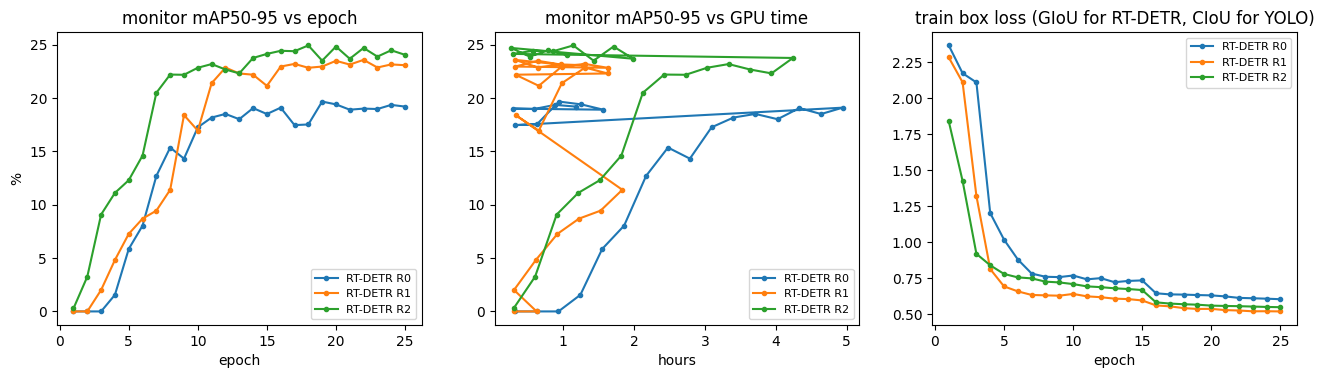

In [9]:
curves = {f"RT-DETR {n}": RUNS_DIR / n / "results.csv" for n in EXPERIMENTS}
curves["YOLOv8s E1 (CNN)"] = WORK_DIR / ("runs_yolo_smoke" if SMOKE else "runs_yolo") / "E1" / "results.csv"
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for label, p in curves.items():
    if not p.exists():
        print("missing:", p); continue
    df = U.training_curve(p.parent)
    style = "s--" if "YOLO" in label else "o-"
    ax[0].plot(df["epoch"], df["metrics/mAP50-95(B)"] * 100, style, label=label, ms=3)
    if "time" in df:
        ax[1].plot(df["time"] / 3600, df["metrics/mAP50-95(B)"] * 100, style, label=label, ms=3)
    ax[2].plot(df["epoch"], df["train/giou_loss"] if "train/giou_loss" in df else df["train/box_loss"], style, label=label, ms=3)
ax[0].set(title="monitor mAP50-95 vs epoch", xlabel="epoch", ylabel="%")
ax[1].set(title="monitor mAP50-95 vs GPU time", xlabel="hours")
ax[2].set(title="train box loss (GIoU for RT-DETR, CIoU for YOLO)", xlabel="epoch")
for a in ax: a.legend(fontsize=8)
fig.savefig(FIG_DIR / "rtdetr_vs_cnn_curves.png", bbox_inches="tight"); plt.show()

> **Observation.** R2 (no denoising) is best: 23.4 mAP vs 17.9 for R0 and 22.7 for R1, with much better localisation (AP75 20.4 vs
> 12.9). 500 queries (R1) give the best AP_small (12.2) and help rare classes (bus 10.0, van 27.6), but localise worse
> than R2. Dynamics: monitor mAP stays at 0 for 3 epochs in R0 and 2 in R1, while R2 rises from epoch 2; all runs
> level off after epochs 12–15, so 25 epochs were enough. YOLO's curve is missing in this run (its `results.csv` was not
> copied); in notebook 02 YOLO E1 is at ≈20% monitor mAP already after epoch 1. The GPU-hours plot is distorted by the
> resumed runs: the clock restarts after each resume.

## 6. Small objects and dense scenes
AP by object size comes from the results table above. For density, every val frame is put into a bucket by its
number of objects and the recall of confident detections (score ≥ 0.3) is averaged per bucket.
YOLO's predictions are included when `runs_yolo/E1/val_preds.csv.gz` is on this Drive.

In [10]:
BEST = res["mAP"].astype(float).idxmax()
pred_files = {f"RT-DETR {n}": RUNS_DIR / n / "val_preds.csv.gz" for n in EXPERIMENTS}
pred_files["YOLOv8s E1"] = WORK_DIR / ("runs_yolo_smoke" if SMOKE else "runs_yolo") / "E1" / "val_preds.csv.gz"
bins, labels = [0, 20, 50, 80, 1000], ["<20", "20-50", "50-80", ">80"]
dens, errs = {}, {}
for label, p in pred_files.items():
    if not p.exists(): continue
    errs[label] = AN.error_breakdown(pd.read_csv(p), val, score_thr=0.3)
    pf = errs[label]["per_frame"].dropna()
    dens[label] = pf.groupby(pd.cut(pf["n_gt"], bins, labels=labels), observed=False)["recall"].mean()
dens_df = (pd.DataFrame(dens).T * 100).round(1)
dens_df.columns = [f"recall, {c} objects/frame" for c in dens_df.columns]
display(dens_df)
pd.DataFrame({k: e["detections"]["share_%"] for k, e in errs.items()}).fillna(0).T

,"recall, <20 objects/frame","recall, 20-50 objects/frame","recall, 50-80 objects/frame","recall, >80 objects/frame"
RT-DETR R0,40.9,69.6,68.3,72.6
RT-DETR R1,32.7,69.8,70.7,75.3
RT-DETR R2,37.1,70.4,71.8,76.7
YOLOv8s E1,16.0,59.1,62.0,67.0


,background,class,duplicate,ignored,location,tp
RT-DETR R0,21.5,8.6,6.2,14.8,13.4,35.5
RT-DETR R1,18.8,9.7,4.5,15.2,11.7,40.1
RT-DETR R2,19.8,9.1,4.8,12.9,11.5,41.9
YOLOv8s E1,10.3,9.3,0.3,11.4,9.1,59.6


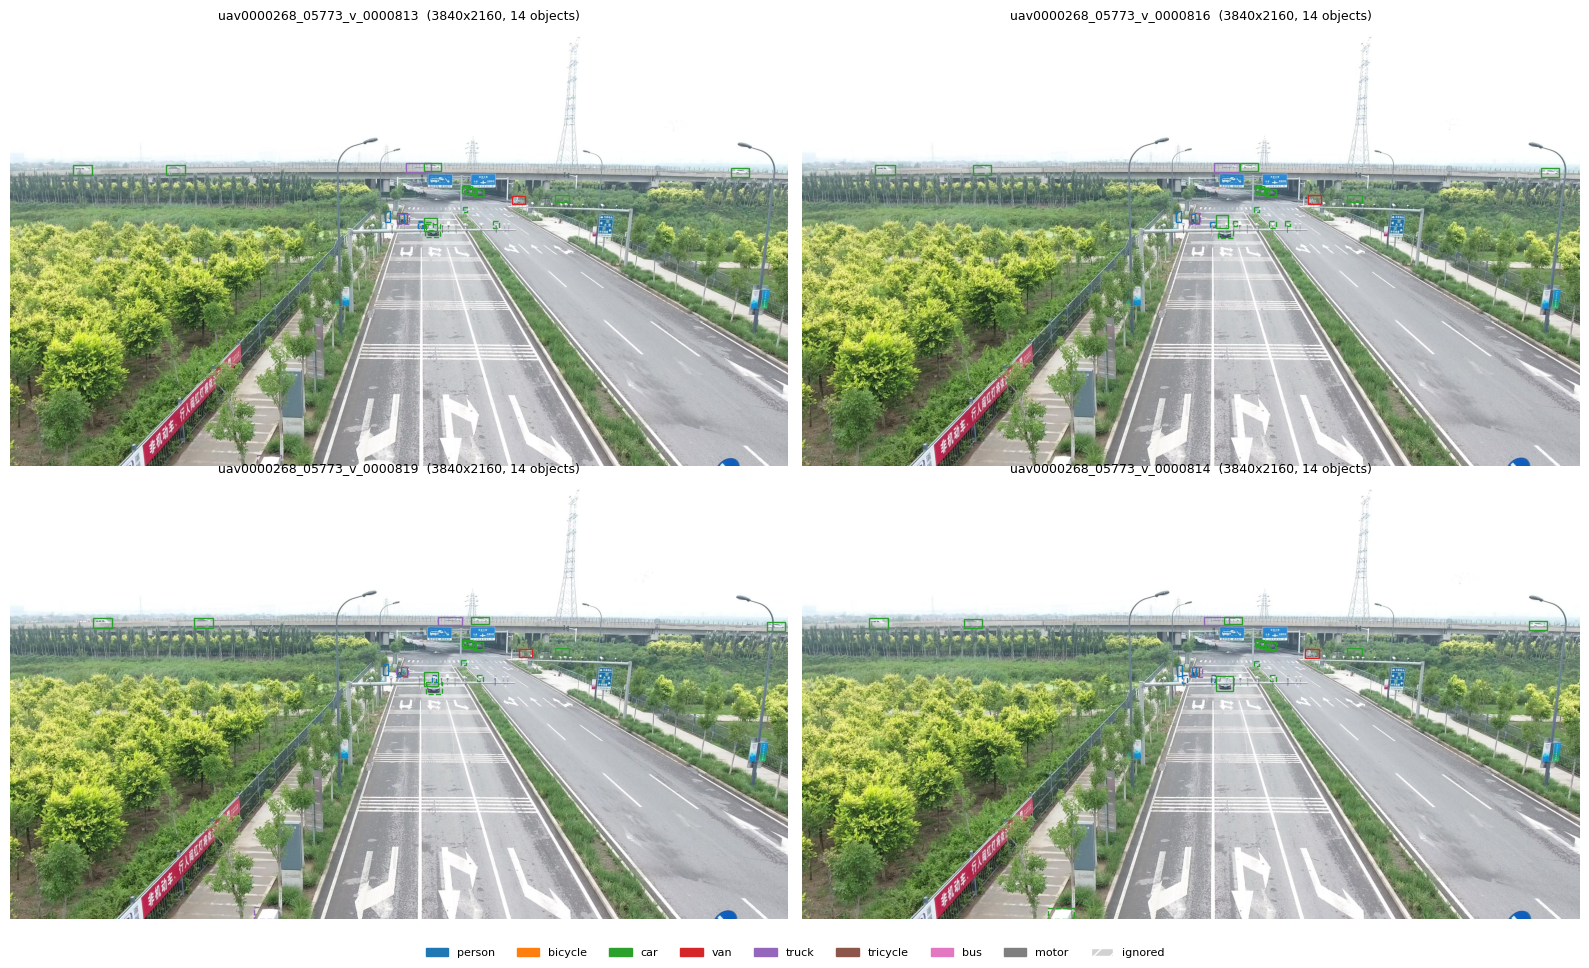

In [11]:
# Worst frames of the best RT-DETR run, predictions dashed (score >= 0.3)
best_label = f"RT-DETR {BEST}"
pf = errs[best_label]["per_frame"].dropna().sort_values("recall")
preds = pd.read_csv(pred_files[best_label])
fig = V.show_frames(val, pf.key.iloc[:4].tolist(), preds=preds, score_thr=0.3, cols=2, size=8)
fig.savefig(FIG_DIR / "rtdetr_worst_frames.png", bbox_inches="tight"); plt.show()

> **Observation.** RT-DETR finds more objects in frames of every density: recall (score ≥ 0.3) is 76.7% vs 67.0% for YOLO in frames
> with more than 80 objects and 37.1% vs 16.0% in frames with fewer than 20. Recall grows with density for all models,
> because the sparse val frames are mostly from the 4K clip with tiny distant objects. Its confident detections are less
> clean than YOLO's (true positives 41.9% vs 59.6%, background 19.8% vs 10.3%), and 4.8% are duplicates despite no NMS.
> On small objects RT-DETR is not better (AP_small 10.8 vs 12.7 for YOLO); its gain comes from medium and large objects.

## 7. Test predictions and submission (best run)

In [12]:
test = D.load_test_images(DATA_ROOT)
if SMOKE:
    test = test.groupby("clip").head(2)
model = RTDETR(str(RUNS_DIR / BEST / "weights" / "last.pt"))
test_preds, sec = U.predict_table(model, test, imgsz=IMGSZ, max_det=500, batch=BATCH, half=DEVICE == 0, desc="test")
test_preds.to_csv(WORK_DIR / f"test_preds_rtdetr_{BEST}.csv.gz", index=False)
if not SMOKE:
    sub = S.write_submission(test_preds, DATA_ROOT, WORK_DIR / f"submission_rtdetr_{BEST}.csv")
    display(sub.head(3))
print(f"best: {BEST} | {len(test_preds)} detections on {test.key.nunique()} test frames, {sec*1000:.0f} ms/img")

test:   0%|          | 0/953 [00:00<?, ?it/s]

saved /content/drive/.shortcut-targets-by-id/1xoiYMFpEHDrVSR-YCbG4KIx7_6dNXsqs/visdrone-work/submission_rtdetr_R2.csv: 3811 rows, 1143300 detections, 0 empty rows


,image_id,PredictionString
0,clip_001_0000001,0 0.8428 630.3 916.0 66.9 164.0 0 0.8311 723.2...
1,clip_001_0000002,0 0.8379 625.1 922.4 66.1 157.6 0 0.8345 720.2...
2,clip_001_0000003,0 0.8389 613.3 932.5 67.2 147.5 0 0.8379 713.8...


best: R2 | 1143300 detections on 3811 test frames, 84 ms/img


## 8. Summary

Hungarian matching computes a cost (classification + L1 + GIoU) between every query and every ground-truth box and
picks the one-to-one assignment with the lowest total cost. Only the matched query learns the object; all other
queries learn "no object", so a second prediction of the same object is penalised in training and NMS is not needed
(a few duplicates remain: 4.8% of confident boxes). Compared with YOLO, training starts slowly (0 mAP for 2–3
epochs while the matching stabilises), but the model converged within 25 epochs and ended higher (23.4 vs 19.8 mAP).
More queries helped small objects and rare classes slightly; removing denoising helped most (+5.5 mAP). This is the
opposite of the DN-DETR result; our hypothesis is that with up to 180 objects per frame, 100 denoising groups add very
many extra queries and their loss dominates training. RT-DETR is better in dense frames and on medium/large objects;
YOLO stays better on small ones. **R2 goes forward:** public LB 0.2583.